# 02 - Vector Operations

This notebook demonstrates the reusable 2D/3D numeric vector API in `quantum_space_agi.scientific.vector`.

For vectors $\mathbf{u}$ and $\mathbf{v}$:

- Addition: $\mathbf{u}+\mathbf{v}$
- Dot product: $\mathbf{u}\cdot\mathbf{v}=\sum_i u_i v_i$
- Magnitude: $\|\mathbf{u}\|=\sqrt{\sum_i u_i^2}$
- Cross product: $\mathbf{u}\times\mathbf{v}$ is defined for 3D vectors and follows the right-hand rule.

Vectors are numeric and carry no units or coordinate-frame metadata.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd()
repo_root = next((p for p in (cwd, *cwd.parents) if (p / "src").is_dir()), cwd)
sys.path.insert(0, str(repo_root / "src"))

import numpy as np
import matplotlib.pyplot as plt
from quantum_space_agi.scientific import is_close
from quantum_space_agi.scientific.vector import (
    add, cross, distance, dot, magnitude, normalize, scale, subtract,
)


## Basic vector arithmetic

The implementation returns independent `Float64` NumPy arrays and rejects non-finite results and mismatched dimensions.

In [2]:
u = [1.0, 2.0, 3.0]
v = [4.0, 5.0, 6.0]

print("sum:", add(u, v))
print("difference:", subtract(v, u))
print("scaled:", scale(u, 2.5))
print("dot:", dot(u, v))
print("cross:", cross(u, v))
print("magnitudes:", magnitude(u), magnitude(v))
print("distance:", distance(u, v))
print("normalized u:", normalize(u))


sum: [5. 7. 9.]
difference: [3. 3. 3.]
scaled: [2.5 5.  7.5]
dot: 32.0
cross: [-3.  6. -3.]
magnitudes: 3.7416573867739413 8.774964387392123
distance: 5.196152422706632
normalized u: [0.26726124 0.53452248 0.80178373]


**Expected values:**

- Sum: `[5, 7, 9]`
- Difference: `[3, 3, 3]`
- Dot product: `32`
- Cross product: `[-3, 6, -3]`
- Distance from `u` to `v`: `sqrt(27)` approximately `5.196152`


In [3]:
assert np.allclose(add(u, v), [5, 7, 9])
assert dot(u, v) == 32.0
assert np.allclose(cross(u, v), [-3, 6, -3])
assert is_close(distance(u, v), np.sqrt(27))

print("Vector validation examples passed.")


Vector validation examples passed.


## Visualization: 2D vectors and their sum

A quiver plot shows vector addition geometrically. The axes do not imply physical units.

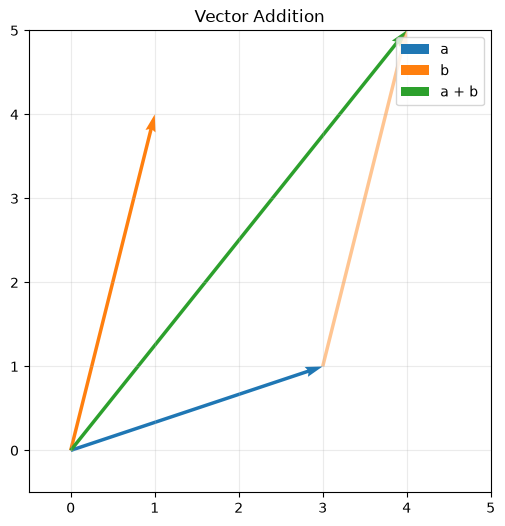

In [4]:
a = np.array([3.0, 1.0])
b = np.array([1.0, 4.0])
result = add(a, b)

fig, ax = plt.subplots(figsize=(6, 6))
ax.quiver(0, 0, a[0], a[1], angles="xy", scale_units="xy", scale=1, color="C0", label="a")
ax.quiver(0, 0, b[0], b[1], angles="xy", scale_units="xy", scale=1, color="C1", label="b")
ax.quiver(0, 0, result[0], result[1], angles="xy", scale_units="xy", scale=1, color="C2", label="a + b")
ax.quiver(a[0], a[1], b[0], b[1], angles="xy", scale_units="xy", scale=1, color="C1", alpha=0.45)
ax.set_aspect("equal")
ax.set_xlim(-0.5, 5)
ax.set_ylim(-0.5, 5)
ax.grid(True, alpha=0.25)
ax.legend()
ax.set_title("Vector Addition")
plt.show()


## Numerical limitations

- Only 2D and 3D vectors are accepted by the public vector API.
- The cross product rejects 2D inputs even though NumPy has a separate legacy behavior.
- Magnitude uses overflow-resistant `math.hypot` summation.
- Dot, addition, subtraction, and scaling reject non-finite results.
- Normalize rejects a zero vector and can amplify roundoff for extremely small but non-zero vectors.